In [1]:
pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
    --------------------------------------- 0.8/48.9 MB 6.0 MB/s eta 0:00:09
   -- ------------------------------------- 3.1/48.9 MB 8.0 MB/s eta 0:00:06
   ---- ----------------------------------- 5.0/48.9 MB 8.4 MB/s eta 0:00:06
   ----- ---------------------------------- 6.8/48.9 MB 8.8 MB/s eta 0:00:05
   ------- -------------------------------- 8.7/48.9 MB 8.5 MB/s eta 0:00:05
   ------- -------------------------------- 9.7/48.9 MB 8.0 MB/s eta 0:00:05
   -------- ------------------------------- 10.2/48.9 MB 7.4 MB/s eta 0:00:06
   -------- ------------------------------- 10.7/48.9 MB 6.9 MB/s eta 0:00:06
   -------- ------------------------------- 11.0/48.9 MB 6.3 MB/s eta 0:00:07
   --------- ------------------------------ 11.3/48.9 MB 5.8 MB/s eta 0:00:07
   --------- ------------------------------ 11.5/48.9 MB 5.4 MB/s eta 0:00:07
   -----


[notice] A new release of pip is available: 26.0 -> 26.3
[notice] To update, run: C:\Users\nandu\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


(1372, 8) (90, 8) 0
  Model Train data  MAE  RMSE  MAPE %
XGBoost        raw 3.88  4.70   22.60
XGBoost   filtered 4.28  5.38   25.05


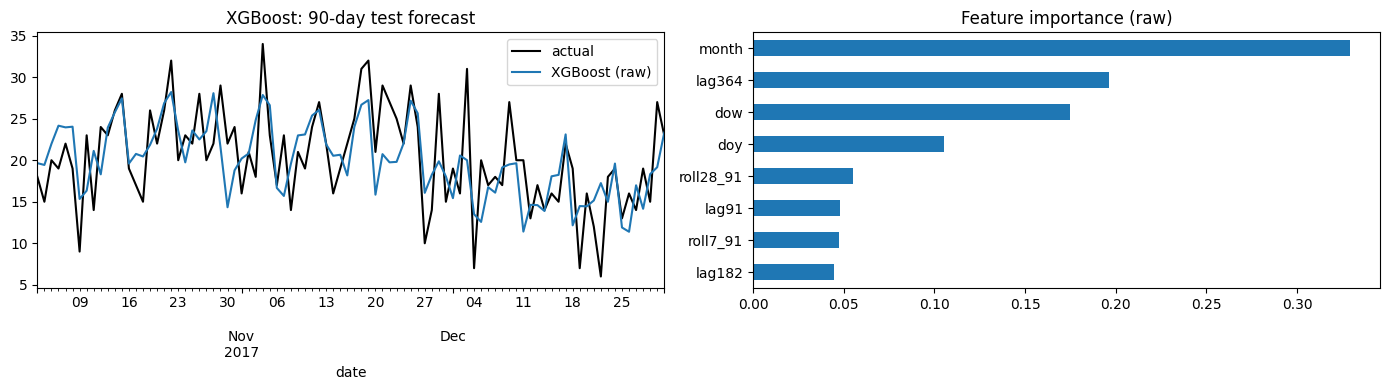

In [2]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from xgboost import XGBRegressor

rd = lambda f: pd.read_csv(f"../data/{f}", parse_dates=["date"], index_col="date")["sales"].asfreq("D")
train_raw, train_f, test = rd("train_raw.csv"), rd("train_filtered.csv"), rd("test_raw.csv")
full = pd.concat([train_raw, test])

def metrics(y, p):
    return (np.mean(np.abs(y-p)), np.sqrt(np.mean((y-p)**2)), np.mean(np.abs((y-p)/y))*100)

# Features known at forecast time: calendar + lags >= 91 days (multiples of 7 keep weekday alignment)
f = pd.DataFrame(index=full.index)
f["dow"], f["month"], f["doy"] = full.index.dayofweek, full.index.month, full.index.dayofyear
for L in [91, 182, 364]:
    f[f"lag{L}"] = full.shift(L)
f["roll7_91"]  = full.shift(91).rolling(7).mean()
f["roll28_91"] = full.shift(91).rolling(28).mean()

X_all = f.dropna()
X_tr = X_all.loc[X_all.index.isin(train_raw.index)]
X_te = f.loc[test.index]
print(X_tr.shape, X_te.shape, X_te.isna().sum().sum())  # expect NaN count 0

rows, preds = [], {}
for tname, tr in {"raw": train_raw, "filtered": train_f}.items():
    m = XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=4,
                     subsample=0.8, colsample_bytree=0.8, random_state=42)
    m.fit(X_tr, tr.loc[X_tr.index])
    p = m.predict(X_te)
    preds[f"XGBoost ({tname})"] = p
    rows.append(["XGBoost", tname, *metrics(test.values, p)])
    if tname == "raw":
        imp = pd.Series(m.feature_importances_, index=X_tr.columns).sort_values()

res = pd.DataFrame(rows, columns=["Model","Train data","MAE","RMSE","MAPE %"]).round(2)
print(res.to_string(index=False))

pd.DataFrame(preds, index=test.index).to_csv("../outputs/preds_xgb.csv")
res.to_csv("../outputs/results_xgb.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
test.plot(ax=ax[0], color="black", label="actual")
pd.Series(preds["XGBoost (raw)"], index=test.index).plot(ax=ax[0], label="XGBoost (raw)")
ax[0].legend(); ax[0].set_title("XGBoost: 90-day test forecast")
imp.plot.barh(ax=ax[1], title="Feature importance (raw)")
plt.tight_layout(); plt.savefig("../outputs/05_xgb.png", dpi=150)